# 03 · Prueba con datos nuevos

**Objetivo:** evaluar el modelo final, sin reentrenarlo, con anuncios que no ha visto nunca, procedentes de la versión completa del dataset (100.000 anuncios). Se eliminan los anuncios que ya estaban en la versión de 10.000 usada para entrenar, para que la prueba sea totalmente independiente.

In [8]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from scrips.cleaning import load_raw_data, clean_data
from scrips.modeling import split_features_target, get_state_dummies, build_final_features, load_artifacts
from sklearn.model_selection import train_test_split

In [ ]:
- Cargar los archivos

In [2]:
apartments_10k = load_raw_data("../data/raw/apartments_for_rent_classified_10K.csv")
apartments_100k = load_raw_data("../data/raw/apartments_for_rent_classified_100K.csv")

print("Archivo de 10.000: ", apartments_10k.shape)
print("Archivo de 100.000:", apartments_100k.shape)

Archivo de 10.000:  (10000, 22)
Archivo de 100.000: (99492, 22)


c:\data-analytics\unidad7\Apartment-rent-predictor\notebooks\..\scrips\cleaning.py:19: DtypeWarning: Columns (0: address) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, sep=";", encoding="cp1252")


- Quitar los anuncios que el modelo ya conoce.
Debido que son datos del mismo Apartment for Rend Classifield, Es probable que los 10k archivos con los que se entreno el modelo sean una muesta de los 100k, por lo que si no quitamos los id que se repiten, inflaria el resultado.

In [3]:
ids_seen = set(apartments_10k["id"])
already_seen = apartments_100k["id"].isin(ids_seen)

print("Anuncios del archivo grande que ya estaban en el de 10.000:", already_seen.sum())

new_listings = apartments_100k[~already_seen]
print("Anuncios nuevos:", new_listings.shape[0])

Anuncios del archivo grande que ya estaban en el de 10.000: 9983
Anuncios nuevos: 89509


**Observación:** 9.983 de los 10.000 anuncios del dataset de entrenamiento están también en la versión de 100.000, lo que confirma que es una muestra de ella. Se eliminan para que la prueba sea independiente: quedan 89.509 anuncios nuevos, casi 9 veces mas de los datos con los que se entreno el modelo

- Limpieza con el pipeline

In [4]:
new_clean = clean_data(new_listings)
new_clean.shape

(88913, 40)

88.913 tras aplicar el mismo pipeline de limpieza.

- Preparar las variables del modelo

In [5]:
model, model_columns = load_artifacts("../models/rent_model.pkl", "../models/model_columns.pkl")

X_new, y_new = split_features_target(new_clean)
state_dummies_new = get_state_dummies(new_clean)
X_new_final = build_final_features(X_new, state_dummies_new).reindex(columns=model_columns, fill_value=0)

print("¿Mismas columnas que el modelo?", list(X_new_final.columns) == list(model_columns))

¿Mismas columnas que el modelo? True


- Predecir y Evaluar

In [6]:
pred_new = model.predict(X_new_final)

print("R²:  ", round(r2_score(y_new, pred_new), 3))
print("MAE: ", round(mean_absolute_error(y_new, pred_new), 2))
print("RMSE:", round(float(np.sqrt(mean_squared_error(y_new, pred_new))), 2))

R²:   0.668
MAE:  3.29
RMSE: 5.1


### Comparación: test frente a datos nuevos

| Evaluación | Anuncios evaluados | R² | MAE ($/m²) | RMSE ($/m²) | Error medio en un piso de 75 m² |
|---|---|---|---|---|---|
| Test (20% del dataset de 10.000) | 1.970 | 0,794 | 3,03 | 4,87 | ~227 $/mes |
| Datos nuevos (dataset de 100.000) | 88.913 | 0,668 | 3,29 | 5,10 | ~247 $/mes |
| **Diferencia** | | **−0,126** | **+0,26 (+9%)** | **+0,23 (+5%)** | **+20 $/mes** |

*El modelo se entrenó con 7.878 anuncios (80% del dataset de 10.000). Ninguno de los anuncios evaluados se usó en el entrenamiento.*

**Observación:** con 88.913 anuncios que nunca ha visto, el modelo mantiene un error medio muy similar al del test (MAE de 3,03 a 3,29 $/m², un 9% más; unos 247 $/mes en un piso de 75 m²), lo que confirma que generaliza bien. El R² baja de 0,794 a 0,668, ya que los datos nuevos abarcan muchas más ciudades y mercados, algunos poco representados en los 7.878 anuncios de entrenamiento.

### Análisis del error según el conocimiento de la ciudad

Se comprueba si el aumento del error se debe a ciudades poco representadas en el entrenamiento. Cada anuncio nuevo se clasifica según el número de anuncios de su ciudad que había en el conjunto de entrenamiento (7.878 anuncios), y se calcula el error de cada grupo.

- Anuncios por ciudad en el entrenamiento

In [9]:
apartments_clean = pd.read_csv("../data/clean/apartments_clean.csv")
X, y = split_features_target(apartments_clean)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0)

train_cities = (apartments_clean.loc[X_train.index]
                .groupby(["cityname", "state"])
                .size()
                .rename("train_listings")
                .reset_index())
train_cities.shape

(1575, 3)

- Clasificar los anuncios nuevos

In [10]:
results = new_clean[["cityname", "state"]].copy()
results["real"] = y_new.values
results["pred"] = pred_new

results = results.merge(train_cities, on=["cityname", "state"], how="left")
results["train_listings"] = results["train_listings"].fillna(0)

results["group"] = pd.cut(results["train_listings"],
                          bins=[-1, 0, 4, 19, np.inf],
                          labels=["Ciudad nueva (0)", "1–4 anuncios", "5–19 anuncios", "20 o más"])
results["group"].value_counts().sort_index()

group
Ciudad nueva (0)    13066
1–4 anuncios        23150
5–19 anuncios       22995
20 o más            29702
Name: count, dtype: int64

- Error por grupo

In [11]:
summary = results.groupby("group", observed=True).apply(
    lambda g: pd.Series({"Anuncios": len(g),
                         "MAE": mean_absolute_error(g["real"], g["pred"]),
                         "R²": r2_score(g["real"], g["pred"])}))
summary.round({"Anuncios": 0, "MAE": 2, "R²": 3})

,Anuncios,MAE,R²
group,,,
Ciudad nueva (0),13066.0,3.62,0.529
1–4 anuncios,23150.0,3.31,0.608
5–19 anuncios,22995.0,2.81,0.711
20 o más,29702.0,3.49,0.713


- Gráfico

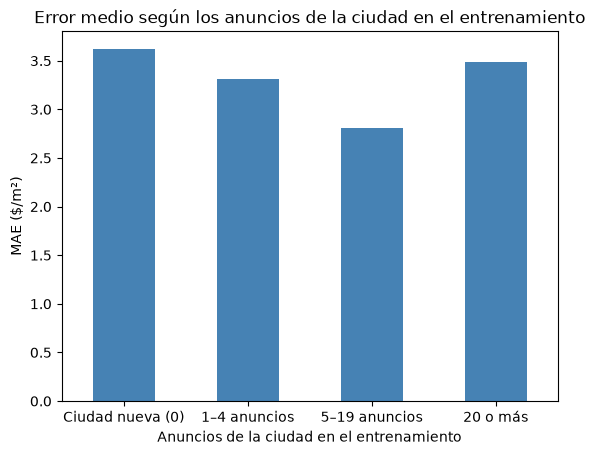

In [12]:
import matplotlib.pyplot as plt

summary["MAE"].plot(kind="bar", color="steelblue")
plt.title("Error medio según los anuncios de la ciudad en el entrenamiento")
plt.xlabel("Anuncios de la ciudad en el entrenamiento")
plt.ylabel("MAE ($/m²)")
plt.xticks(rotation=0)
plt.show()

In [13]:
summary["Precio medio ($/m²)"] = results.groupby("group", observed=True)["real"].mean()
summary["Error relativo (%)"] = summary["MAE"] / summary["Precio medio ($/m²)"] * 100
summary.round({"Anuncios": 0, "MAE": 2, "R²": 3, "Precio medio ($/m²)": 2, "Error relativo (%)": 1})

,Anuncios,MAE,R²,Precio medio ($/m²),Error relativo (%)
group,,,,,
Ciudad nueva (0),13066.0,3.62,0.529,16.83,21.5
1–4 anuncios,23150.0,3.31,0.608,17.78,18.6
5–19 anuncios,22995.0,2.81,0.711,17.28,16.3
20 o más,29702.0,3.49,0.713,19.34,18.0


**Observación:** el R² aumenta claramente a medida que el modelo conoce mejor la ciudad: de 0,529 en ciudades que no vio nunca a 0,711–0,713 en ciudades con 5 o más anuncios de entrenamiento, un nivel cercano al del test. Las ciudades nuevas son el grupo con peores resultados en todas las métricas (error relativo del 21,5%, frente al 16,3–18,6% del resto), lo que confirma que la bajada del R² en los datos nuevos se debe principalmente a mercados poco representados en el entrenamiento.

El grupo de 20 o más anuncios presenta un MAE mayor que el de 5–19, pese a tener el mejor R². Una parte se explica por sus precios más altos (19,34 $/m² de media), pero no toda: su error relativo (18,0%) sigue siendo superior. Que el R² sea el más alto con un error mayor indica que en estas ciudades los precios varían mucho más entre sí. El modelo explica bien esa variación, pero no la captura por completo con las variables disponibles.

Ambos resultados apuntan a la misma mejora: más datos para los mercados poco representados y variables urbanas a escala de barrio (distancia al centro, al transporte o a servicios).

## Conclusiones

1. El modelo final, sin reentrenar, mantiene un error medio similar con 88.913 anuncios nuevos (MAE de 3,03 a 3,29 $/m²), lo que confirma que generaliza bien.
2. La bajada del R² (de 0,794 a 0,668) se concentra en las ciudades poco o nada representadas en el entrenamiento.
3. El rendimiento está limitado por los datos disponibles, no por el modelo: reentrenar con la versión completa del dataset (100.000 anuncios, frente a los 10.000 usados) e incorporar variables urbanas son las mejoras con más potencial.